# 01 – Data Understanding & Exploratory Data Analysis (EDA)

**Project:** Analisis Pola Persebaran Catatan Keanekaragaman Hayati di Indonesia Menggunakan Metode Clustering  
**Tahap ML Lifecycle:** [L] Learning Problem  
**Sumber data:** GBIF – Indonesia Occurrence Data  
**Periode kajian:** 2015–2025

Notebook ini digunakan untuk memahami struktur, kelengkapan, kualitas, dan pola awal catatan kemunculan spesies. Karena tujuan project adalah **clustering**, kolom `class` dan `kingdom` hanya digunakan sebagai informasi deskriptif/EDA, bukan sebagai target prediksi.

## 1. Import Library

Bagian ini memanggil library untuk membaca dan memeriksa data, melakukan perhitungan numerik, serta membuat visualisasi EDA.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import zipfile
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
TAHUN_AWAL = 2015
TAHUN_AKHIR = 2025

print("Library berhasil diimpor.")

Library berhasil diimpor.


## 2. Menentukan Lokasi dan Membaca Dataset GBIF

Bagian ini mencari file ZIP hasil unduhan GBIF di Google Colab, memeriksa isi arsip, lalu membaca kolom yang diperlukan saja agar penggunaan memori lebih efisien. GBIF Simple CSV menggunakan pemisah tab (`\t`), meskipun file di dalam arsip dapat memiliki ekstensi `.csv`.

In [2]:
# Nama file ZIP GBIF yang diunduh
NAMA_ZIP = "0001923-261110092616502.zip"

FOLDER_DATA = Path("/content/sample_data")
FOLDER_ALTERNATIF = Path("/content")

# Mencari file ZIP tanpa membuat path ZIP/ZIP yang keliru.
folder_pencarian = [FOLDER_DATA, FOLDER_ALTERNATIF]
kandidat_zip = []
for folder in folder_pencarian:
    if folder.exists():
        kandidat_zip.extend(folder.glob("*.zip"))

# Hilangkan path duplikat jika folder pencarian saling berkaitan.
kandidat_zip = list(dict.fromkeys(kandidat_zip))
lokasi_zip = FOLDER_DATA / NAMA_ZIP

if not lokasi_zip.exists():
    kandidat_cocok = [p for p in kandidat_zip if NAMA_ZIP in p.name or "0001923-261110092616502" in p.name]
    if kandidat_cocok:
        lokasi_zip = kandidat_cocok[0]
    elif len(kandidat_zip) == 1:
        lokasi_zip = kandidat_zip[0]
    else:
        daftar_nama = [p.name for p in kandidat_zip]
        raise FileNotFoundError(
            "ZIP GBIF tidak ditemukan. Pastikan file diunggah ke /content/sample_data "
            "atau /content. ZIP yang terdeteksi: " + str(daftar_nama)
        )

if not zipfile.is_zipfile(lokasi_zip):
    raise ValueError(f"File yang dipilih bukan arsip ZIP yang valid: {lokasi_zip}")

print("File ZIP:", lokasi_zip.name)
print("Lokasi ZIP:", lokasi_zip)
print("Ukuran ZIP (MB):", round(lokasi_zip.stat().st_size / (1024 ** 2), 2))

# Kolom yang diperlukan untuk EDA dan persiapan analisis clustering.
kolom_eda = [
    "gbifID", "kingdom", "phylum", "class", "order", "family", "genus",
    "species", "taxonRank", "countryCode", "stateProvince", "occurrenceStatus",
    "decimalLatitude", "decimalLongitude", "coordinateUncertaintyInMeters",
    "depth", "day", "month", "year", "basisOfRecord", "individualCount", "issue"
]

# Membaca file occurrence di dalam ZIP. GBIF Simple CSV memakai tab (\t)
# sebagai pemisah, meskipun ekstensi file umumnya .csv atau .txt.
with zipfile.ZipFile(lokasi_zip, "r") as arsip:
    daftar_data = [
        info for info in arsip.infolist()
        if info.filename.lower().endswith((".csv", ".tsv", ".txt")) and not info.is_dir()
    ]
    if not daftar_data:
        raise ValueError("Tidak ditemukan file tabel CSV/TSV/TXT di dalam ZIP GBIF.")

    # Utamakan occurrence.txt/csv jika tersedia; jika tidak, pilih tabel terbesar.
    kandidat_occurrence = [
        info for info in daftar_data
        if Path(info.filename).name.lower().startswith("occurrence")
    ]
    info_data = max(kandidat_occurrence or daftar_data, key=lambda item: item.file_size)

   # membaca header
    with arsip.open(info_data.filename) as f_header:
        kolom_sumber = pd.read_csv(f_header, sep="\t", nrows=0, low_memory=False).columns.tolist()

    kolom_dibaca = [kolom for kolom in kolom_eda if kolom in kolom_sumber]
    if not kolom_dibaca:
        raise ValueError(
            "Tidak ada kolom GBIF yang cocok dengan daftar kolom EDA. "
            "Periksa apakah file yang dipilih merupakan occurrence data GBIF."
        )

    with arsip.open(info_data.filename) as f_data:
        df = pd.read_csv(
            f_data,
            sep="\t",
            usecols=kolom_dibaca,
            low_memory=False
        )

kolom_tidak_tersedia = [kolom for kolom in kolom_eda if kolom not in kolom_sumber]

# Memastikan variabel utama terbentuk sebelum notebook melanjutkan ke EDA.
assert isinstance(df, pd.DataFrame), "Data GBIF gagal dimuat menjadi DataFrame."

print("File tabel di dalam ZIP:", info_data.filename)
print("Jumlah baris:", f"{len(df):,}")
print("Jumlah kolom pada file sumber:", len(kolom_sumber))
print("Jumlah kolom yang dimuat untuk EDA:", len(df.columns))
print("Kolom yang tidak tersedia (jika ada):", kolom_tidak_tersedia)
display(df.head())

File ZIP: 0001923-261110092616502.zip
Lokasi ZIP: /content/sample_data/0001923-261110092616502.zip
Ukuran ZIP (MB): 240.99
File tabel di dalam ZIP: 0001923-261110092616502.csv
Jumlah baris: 2,022,875
Jumlah kolom pada file sumber: 50
Jumlah kolom yang dimuat untuk EDA: 22
Kolom yang tidak tersedia (jika ada): []


,gbifID,kingdom,phylum,class,order,family,genus,species,taxonRank,countryCode,stateProvince,occurrenceStatus,individualCount,decimalLatitude,decimalLongitude,coordinateUncertaintyInMeters,depth,day,month,year,basisOfRecord,issue
0,3427261301,Plantae,Tracheophyta,Magnoliopsida,Magnoliales,Annonaceae,Disepalum,Disepalum rawagambut,SPECIES,ID,Sumatera Province,DETECTED,1.000,-1.771,104.202,NaN,NaN,30.000,11.000,2020,MATERIAL_CITATION,OCCURRENCE_STATUS_INFERRED_FROM_INDIVIDUAL_COUNT;GEODETIC_DATUM_ASSUMED_WGS84;CONTINENT_DERIVED_...
1,4740657999,Animalia,Chordata,Aves,Coraciiformes,Alcedinidae,Todiramphus,Todiramphus chloris,SPECIES,ID,Sulawesi,DETECTED,1.000,0.473,121.437,NaN,NaN,28.000,10.000,2023,HUMAN_OBSERVATION,COORDINATE_ROUNDED;GEODETIC_DATUM_ASSUMED_WGS84;CONTINENT_DERIVED_FROM_COORDINATES;TAXON_CONCEPT...
2,4747492628,Animalia,Chordata,Aves,Charadriiformes,Turnicidae,Turnix,Turnix suscitator,SPECIES,ID,Sulawesi,DETECTED,2.000,-0.414,121.866,NaN,NaN,18.000,11.000,2023,HUMAN_OBSERVATION,COORDINATE_ROUNDED;GEODETIC_DATUM_ASSUMED_WGS84;CONTINENT_DERIVED_FROM_COORDINATES;TAXON_CONCEPT...
3,4749612951,Animalia,Chordata,Aves,Passeriformes,Rhipiduridae,Rhipidura,Rhipidura leucophrys,SPECIES,ID,Maluku,DETECTED,1.000,0.915,127.548,NaN,NaN,24.000,6.000,2023,HUMAN_OBSERVATION,COORDINATE_ROUNDED;GEODETIC_DATUM_ASSUMED_WGS84;CONTINENT_DERIVED_FROM_COORDINATES;TAXON_CONCEPT...
4,4749648957,Animalia,Chordata,Aves,Galliformes,Phasianidae,Arborophila,Arborophila javanica,SPECIES,ID,Jawa,DETECTED,3.000,-7.159,107.431,NaN,NaN,18.000,5.000,2023,HUMAN_OBSERVATION,COORDINATE_ROUNDED;GEODETIC_DATUM_ASSUMED_WGS84;CONTINENT_DERIVED_FROM_COORDINATES;TAXON_CONCEPT...


## 3. Informasi Umum Dataset (Bab 4.1)

Bagian ini menampilkan jumlah baris dan kolom pada file sumber, ukuran ZIP, penggunaan memori DataFrame yang dibaca, serta tipe data kolom. Perbedaan antara jumlah kolom sumber dan kolom yang dimuat dijelaskan karena notebook hanya membaca kolom yang relevan.

In [3]:
# Memastikan sel pembacaan ZIP/TSV sudah dijalankan.
variabel_penting = ["lokasi_zip", "info_data", "kolom_sumber", "df"]
variabel_belum_ada = [nama for nama in variabel_penting if nama not in globals()]
if variabel_belum_ada:
    raise RuntimeError(
        "Data GBIF belum dimuat. Jalankan sel 'Menentukan Lokasi dan Membaca Dataset GBIF' "
        "terlebih dahulu (sel 4), lalu jalankan kembali sel ringkasan ini. "
        "Variabel yang belum tersedia: " + ", ".join(variabel_belum_ada)
    )

ukuran_zip_mb = lokasi_zip.stat().st_size / (1024 ** 2)
ukuran_df_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)

ringkasan_dataset = pd.DataFrame({
    "Informasi": [
        "Sumber data", "Nama arsip", "File tabel dalam arsip", "Format arsip",
        "Format tabel", "Jumlah baris sumber", "Jumlah kolom sumber",
        "Jumlah kolom yang dimuat", "Ukuran ZIP (MB)", "Memori DataFrame terpilih (MB)"
    ],
    "Nilai": [
        "GBIF Indonesia", lokasi_zip.name, info_data.filename, "ZIP",
        "Tab-separated values (TSV)", f"{len(df):,}", f"{len(kolom_sumber):,}",
        f"{len(df.columns):,}", round(ukuran_zip_mb, 2), round(ukuran_df_mb, 2)
    ]
})
display(ringkasan_dataset)

print("\nJumlah kolom berdasarkan tipe data yang dimuat:")
display(
    df.dtypes.astype(str)
    .value_counts()
    .rename_axis("Tipe data")
    .reset_index(name="Jumlah kolom")
)

print("\nInformasi struktur DataFrame:")
df.info()

,Informasi,Nilai
0,Sumber data,GBIF Indonesia
1,Nama arsip,0001923-261110092616502.zip
2,File tabel dalam arsip,0001923-261110092616502.csv
3,Format arsip,ZIP
4,Format tabel,Tab-separated values (TSV)
5,Jumlah baris sumber,"2,022,875"
6,Jumlah kolom sumber,50
7,Jumlah kolom yang dimuat,22
8,Ukuran ZIP (MB),240.990
9,Memori DataFrame terpilih (MB),"1,746.750"



Jumlah kolom berdasarkan tipe data yang dimuat:


,Tipe data,Jumlah kolom
0,object,13
1,float64,7
2,int64,2



Informasi struktur DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2022875 entries, 0 to 2022874
Data columns (total 22 columns):
 #   Column                         Dtype  
---  ------                         -----  
 0   gbifID                         int64  
 1   kingdom                        object 
 2   phylum                         object 
 3   class                          object 
 4   order                          object 
 5   family                         object 
 6   genus                          object 
 7   species                        object 
 8   taxonRank                      object 
 9   countryCode                    object 
 10  stateProvince                  object 
 11  occurrenceStatus               object 
 12  individualCount                float64
 13  decimalLatitude                float64
 14  decimalLongitude               float64
 15  coordinateUncertaintyInMeters  float64
 16  depth                          float64
 17  day            

## 4. Deskripsi Kolom yang Relevan (Bab 4.2)

Tabel berikut menjelaskan atribut GBIF yang digunakan untuk memahami kemunculan spesies. Dalam project clustering, atribut taksonomi menjadi dasar penghitungan keragaman, sedangkan lokasi dan tahun menjadi metadata untuk agregasi serta visualisasi.

In [4]:
deskripsi_fitur = pd.DataFrame([
    ["gbifID", "Integer", "Identitas unik catatan kemunculan spesies."],
    ["kingdom", "Kategorikal", "Kelompok taksonomi tingkat kingdom; digunakan untuk komposisi organisme."],
    ["phylum", "Kategorikal", "Filum organisme; informasi taksonomi pendukung."],
    ["class", "Kategorikal", "Kelas taksonomi; digunakan untuk deskripsi dan penghitungan jumlah kelas unik."],
    ["order", "Kategorikal", "Ordo organisme; informasi taksonomi pendukung."],
    ["family", "Kategorikal", "Famili organisme; digunakan menghitung kekayaan famili."],
    ["species", "Kategorikal", "Nama spesies; digunakan menghitung jumlah spesies unik."],
    ["taxonRank", "Kategorikal", "Tingkat taksonomi dari catatan; digunakan untuk memilih catatan tingkat spesies."],
    ["countryCode", "Kategorikal", "Kode negara tempat catatan kemunculan dibuat."],
    ["stateProvince", "Kategorikal", "Informasi provinsi/wilayah administratif dari sumber GBIF."],
    ["occurrenceStatus", "Kategorikal", "Status kemunculan organisme pada catatan."],
    ["decimalLatitude", "Float", "Koordinat lintang lokasi pengamatan."],
    ["decimalLongitude", "Float", "Koordinat bujur lokasi pengamatan."],
    ["coordinateUncertaintyInMeters", "Float", "Perkiraan ketidakpastian koordinat dalam meter."],
    ["depth", "Float", "Kedalaman lokasi jika dicatat; dapat membantu mengidentifikasi catatan perairan."],
    ["day", "Float", "Hari pada tanggal pengamatan."],
    ["month", "Float", "Bulan pada tanggal pengamatan."],
    ["year", "Integer", "Tahun pengamatan; digunakan untuk analisis temporal."],
    ["basisOfRecord", "Kategorikal", "Dasar atau jenis bukti pencatatan organisme."],
    ["individualCount", "Float", "Jumlah individu jika dicatat oleh sumber data."],
    ["issue", "Kategorikal/teks", "Penanda isu kualitas data dari GBIF jika tersedia."]
], columns=["Nama fitur", "Tipe data", "Deskripsi dan peran dalam penelitian"])
display(deskripsi_fitur)

print("Jumlah kolom yang berhasil dimuat:", len(df.columns))

,Nama fitur,Tipe data,Deskripsi dan peran dalam penelitian
0,gbifID,Integer,Identitas unik catatan kemunculan spesies.
1,kingdom,Kategorikal,Kelompok taksonomi tingkat kingdom; digunakan untuk komposisi organisme.
2,phylum,Kategorikal,Filum organisme; informasi taksonomi pendukung.
3,class,Kategorikal,Kelas taksonomi; digunakan untuk deskripsi dan penghitungan jumlah kelas unik.
4,order,Kategorikal,Ordo organisme; informasi taksonomi pendukung.
5,family,Kategorikal,Famili organisme; digunakan menghitung kekayaan famili.
6,species,Kategorikal,Nama spesies; digunakan menghitung jumlah spesies unik.
7,taxonRank,Kategorikal,Tingkat taksonomi dari catatan; digunakan untuk memilih catatan tingkat spesies.
8,countryCode,Kategorikal,Kode negara tempat catatan kemunculan dibuat.
9,stateProvince,Kategorikal,Informasi provinsi/wilayah administratif dari sumber GBIF.


Jumlah kolom yang berhasil dimuat: 22


## 5. Pemeriksaan Missing Values dan Duplikasi (Bab 4.3)

Bagian ini menghitung jumlah serta persentase nilai kosong pada setiap kolom yang dimuat. Duplikasi diperiksa pada seluruh baris dan pada `gbifID` sebagai identitas unik catatan.

In [5]:
missing = pd.DataFrame({
    "Jumlah kosong": df.isna().sum(),
    "Persentase kosong (%)": (df.isna().mean() * 100).round(2)
}).sort_values("Persentase kosong (%)", ascending=False)
display(missing)

print("Duplikat seluruh baris:", f"{df.duplicated().sum():,}")
if "gbifID" in df.columns:
    print("Duplikat gbifID:", f"{df['gbifID'].duplicated().sum():,}")

kolom_penting = [c for c in [
    "species", "family", "kingdom", "class", "taxonRank",
    "decimalLatitude", "decimalLongitude", "year", "basisOfRecord"
] if c in df.columns]
print("\nMissing values pada kolom penting:")
display(missing.loc[kolom_penting])

,Jumlah kosong,Persentase kosong (%)
depth,2013959,99.560
coordinateUncertaintyInMeters,1605558,79.370
individualCount,859838,42.510
species,274084,13.550
genus,243864,12.060
stateProvince,208721,10.320
family,147957,7.310
order,116686,5.770
class,57880,2.860
phylum,41200,2.040


Duplikat seluruh baris: 0
Duplikat gbifID: 0

Missing values pada kolom penting:


,Jumlah kosong,Persentase kosong (%)
species,274084,13.550
family,147957,7.310
kingdom,39686,1.960
class,57880,2.860
taxonRank,442,0.020
decimalLatitude,0,0.000
decimalLongitude,0,0.000
year,0,0.000
basisOfRecord,0,0.000


## 6. Pemeriksaan Validitas Koordinat, Waktu, dan Nilai Ekstrem (Bab 4.3)

Bagian ini memeriksa rentang latitude, longitude, hari, dan bulan. Outlier pada `individualCount` dihitung menggunakan IQR sebagai informasi kualitas data, tetapi tidak otomatis dihapus karena kolom tersebut bukan fitur utama clustering.

In [6]:
df_check = df.copy()
for col in ["decimalLatitude", "decimalLongitude", "day", "month", "year", "individualCount", "coordinateUncertaintyInMeters"]:
    if col in df_check.columns:
        df_check[col] = pd.to_numeric(df_check[col], errors="coerce")

hasil_validasi = {}
if "decimalLatitude" in df_check.columns:
    hasil_validasi["Latitude kosong/tidak valid"] = int((df_check["decimalLatitude"].isna() | ~df_check["decimalLatitude"].between(-90, 90)).sum())
if "decimalLongitude" in df_check.columns:
    hasil_validasi["Longitude kosong/tidak valid"] = int((df_check["decimalLongitude"].isna() | ~df_check["decimalLongitude"].between(-180, 180)).sum())
if "year" in df_check.columns:
    hasil_validasi["Tahun di luar 2015–2025"] = int((~df_check["year"].between(TAHUN_AWAL, TAHUN_AKHIR) & df_check["year"].notna()).sum())
if "day" in df_check.columns:
    hasil_validasi["Hari di luar 1–31"] = int((~df_check["day"].between(1, 31) & df_check["day"].notna()).sum())
if "month" in df_check.columns:
    hasil_validasi["Bulan di luar 1–12"] = int((~df_check["month"].between(1, 12) & df_check["month"].notna()).sum())

if hasil_validasi:
    display(pd.DataFrame(list(hasil_validasi.items()), columns=["Pemeriksaan", "Jumlah data bermasalah"]))
else:
    print("Kolom koordinat/tanggal tidak tersedia untuk pemeriksaan validitas.")

if "individualCount" in df_check.columns:
    s = df_check["individualCount"].dropna()
    if not s.empty:
        q1, q3 = s.quantile([0.25, 0.75])
        batas_atas = q3 + 1.5 * (q3 - q1)
        print(f"Batas atas IQR individualCount: {batas_atas:.2f}")
        print("Jumlah nilai di atas batas IQR:", f"{int((s > batas_atas).sum()):,}")
        print("Catatan: nilai ekstrem tidak otomatis dihapus; individualCount tidak menjadi fitur utama clustering.")

,Pemeriksaan,Jumlah data bermasalah
0,Latitude kosong/tidak valid,0
1,Longitude kosong/tidak valid,0
2,Tahun di luar 2015–2025,0
3,Hari di luar 1–31,0
4,Bulan di luar 1–12,0


Batas atas IQR individualCount: 8.50
Jumlah nilai di atas batas IQR: 108,101
Catatan: nilai ekstrem tidak otomatis dihapus; individualCount tidak menjadi fitur utama clustering.


## 7. Distribusi Kelompok Taksonomi (EDA)

Bagian ini melihat komposisi catatan menurut kingdom dan class. Informasi ini digunakan untuk memahami isi dataset, bukan sebagai label target karena project menerapkan unsupervised learning.

In [7]:
if "kingdom" in df.columns:
    print("Jumlah catatan berdasarkan kingdom:")
    display(df["kingdom"].fillna("Unknown").value_counts().rename_axis("Kingdom").reset_index(name="Jumlah catatan"))

if "class" in df.columns:
    class_counts = df["class"].dropna().astype(str).str.strip().value_counts()
    print("Jumlah kelas taksonomi unik:", int(df["class"].nunique(dropna=True)))
    print("10 kelas dengan catatan terbanyak:")
    display(class_counts.head(10).rename_axis("Class").reset_index(name="Jumlah catatan"))

Jumlah catatan berdasarkan kingdom:


,Kingdom,Jumlah catatan
0,Animalia,1809359
1,Pseudomonadati,70538
2,Plantae,64302
3,Unknown,39686
4,Chromista,15948
5,Bacillati,12388
6,Fungi,6324
7,Methanobacteriati,2968
8,Thermoproteati,836
9,Protozoa,445


Jumlah kelas taksonomi unik: 283
10 kelas dengan catatan terbanyak:


,Class,Jumlah catatan
0,Aves,1317396
1,Insecta,215954
2,Teleostei,108327
3,Magnoliopsida,48104
4,Reptilia,36110
5,Gastropoda,34560
6,Alphaproteobacteria,34205
7,Mammalia,19729
8,Amphibia,17407
9,Arachnida,15579


## 8. EDA 1 – Sepuluh Kelas Taksonomi dengan Catatan Terbanyak

Grafik ini menunjukkan sepuluh kelas taksonomi dengan jumlah catatan terbanyak. Hasilnya membantu mengenali kelompok organisme yang paling banyak terdokumentasi dalam dataset GBIF.

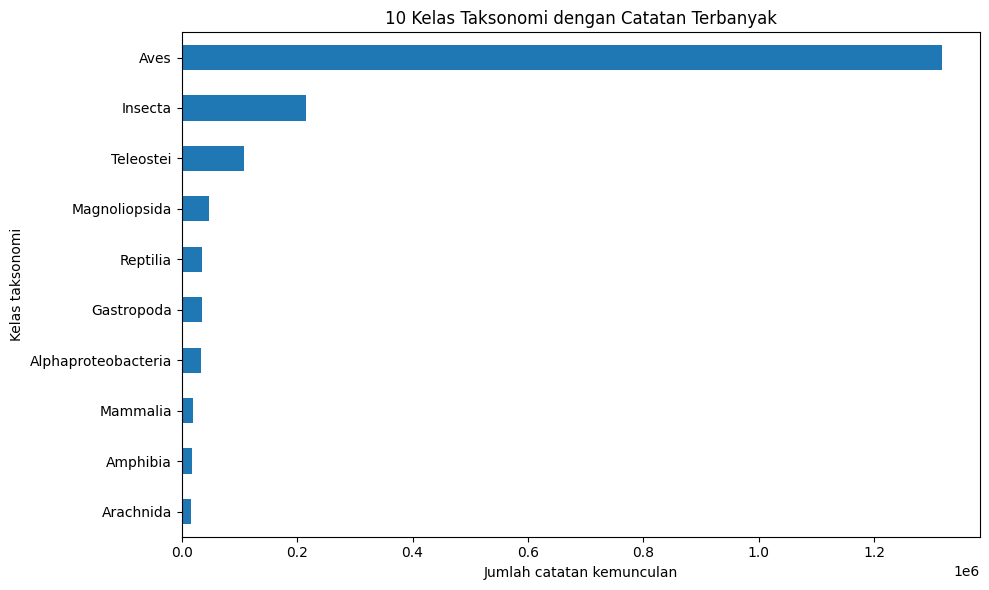

Kelas dengan catatan terbanyak: Aves (1,317,396 catatan).
Interpretasi: jumlah catatan menunjukkan dokumentasi/pengamatan, bukan ukuran populasi sebenarnya.


In [8]:
if "class" in df.columns:
    top_class = df["class"].dropna().astype(str).str.strip().value_counts().head(10).sort_values()
    plt.figure(figsize=(10, 6))
    top_class.plot(kind="barh")
    plt.title("10 Kelas Taksonomi dengan Catatan Terbanyak")
    plt.xlabel("Jumlah catatan kemunculan")
    plt.ylabel("Kelas taksonomi")
    plt.tight_layout()
    plt.show()
    print(f"Kelas dengan catatan terbanyak: {top_class.index[-1]} ({top_class.iloc[-1]:,} catatan).")
    print("Interpretasi: jumlah catatan menunjukkan dokumentasi/pengamatan, bukan ukuran populasi sebenarnya.")

## 9. EDA 2 – Wilayah Administratif dengan Catatan Terbanyak

Grafik ini menampilkan hingga 15 nilai `stateProvince` dengan jumlah catatan tertinggi. Kolom tersebut mengikuti penamaan dari penerbit data GBIF sehingga perlu diperiksa konsistensinya sebelum dianggap sebagai nama provinsi resmi.

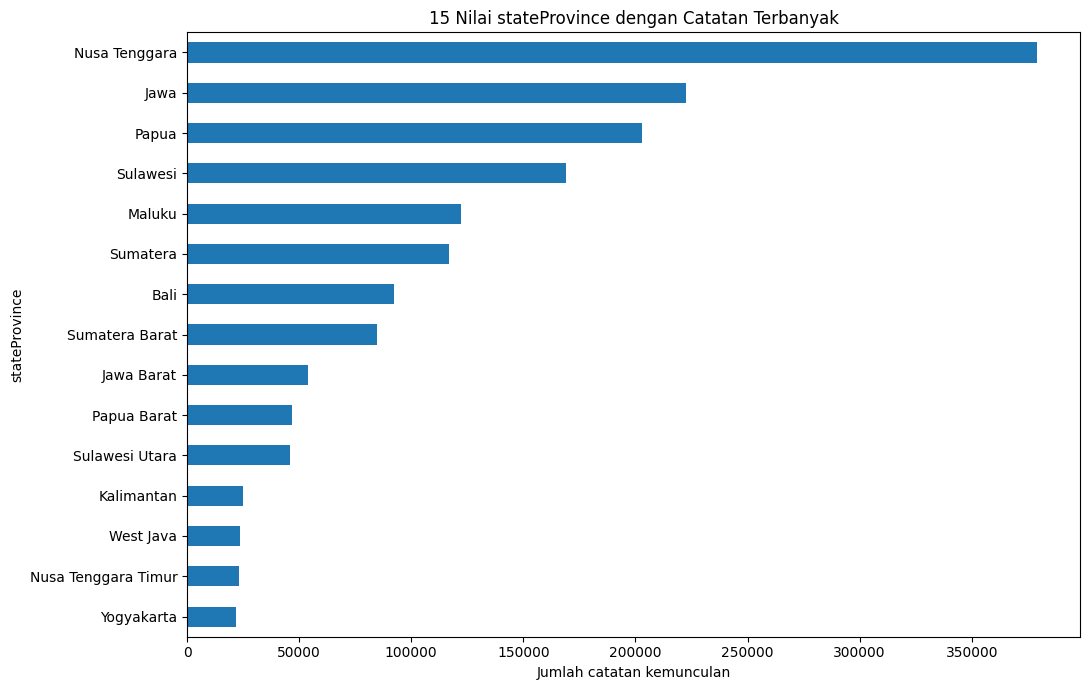

Nilai stateProvince tertinggi: Nusa Tenggara (379,293 catatan).
Catatan: nilai stateProvince belum tentu seluruhnya seragam sebagai nama provinsi administratif.


In [9]:
if "stateProvince" in df.columns:
    top_wilayah = df["stateProvince"].dropna().astype(str).str.strip().value_counts().head(15).sort_values()
    plt.figure(figsize=(11, 7))
    top_wilayah.plot(kind="barh")
    plt.title("15 Nilai stateProvince dengan Catatan Terbanyak")
    plt.xlabel("Jumlah catatan kemunculan")
    plt.ylabel("stateProvince")
    plt.tight_layout()
    plt.show()
    print(f"Nilai stateProvince tertinggi: {top_wilayah.index[-1]} ({top_wilayah.iloc[-1]:,} catatan).")
    print("Catatan: nilai stateProvince belum tentu seluruhnya seragam sebagai nama provinsi administratif.")
else:
    print("Kolom stateProvince tidak tersedia pada dataset.")

## 10. EDA 3 – Tren Catatan Kemunculan per Tahun

Grafik garis ini memperlihatkan perubahan jumlah catatan berdasarkan tahun pengamatan 2015–2025. Grafik digunakan untuk membaca pola dokumentasi dari waktu ke waktu, bukan untuk menyimpulkan perubahan populasi spesies.

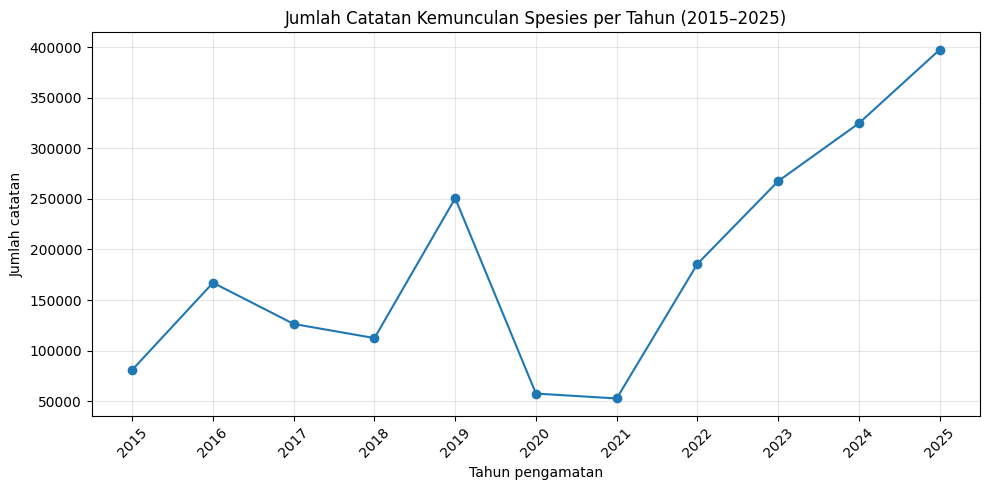

,Jumlah catatan
year,
2015,80997
2016,167063
2017,126312
2018,112366
2019,250632
2020,57490
2021,52665
2022,185717
2023,267491


Tahun dengan catatan terbanyak: 2025 (397,414 catatan).
Tahun dengan catatan paling sedikit: 2021 (52,665 catatan).


In [10]:
if "year" in df.columns:
    data_tahun = pd.to_numeric(df["year"], errors="coerce")
    data_tahun = data_tahun[data_tahun.between(TAHUN_AWAL, TAHUN_AKHIR)].dropna().astype(int)
    jumlah_tahun = data_tahun.value_counts().reindex(range(TAHUN_AWAL, TAHUN_AKHIR + 1), fill_value=0).sort_index()

    plt.figure(figsize=(10, 5))
    plt.plot(jumlah_tahun.index, jumlah_tahun.values, marker="o")
    plt.title("Jumlah Catatan Kemunculan Spesies per Tahun (2015–2025)")
    plt.xlabel("Tahun pengamatan")
    plt.ylabel("Jumlah catatan")
    plt.xticks(jumlah_tahun.index, rotation=45)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    display(jumlah_tahun.rename("Jumlah catatan").to_frame())
    if jumlah_tahun.sum() > 0:
        print(f"Tahun dengan catatan terbanyak: {jumlah_tahun.idxmax()} ({jumlah_tahun.max():,} catatan).")
        print(f"Tahun dengan catatan paling sedikit: {jumlah_tahun.idxmin()} ({jumlah_tahun.min():,} catatan).")
    else:
        print("Tidak ada catatan pada rentang tahun 2015–2025.")
else:
    print("Kolom year tidak tersedia pada dataset.")

## 11. EDA Tambahan – Sebaran Koordinat dan Jenis Bukti Pencatatan

Scatter plot koordinat menggunakan sampel acak agar visualisasi tetap ringan. Grafik `basisOfRecord` digunakan untuk melihat jenis bukti atau cara pencatatan yang paling sering digunakan.

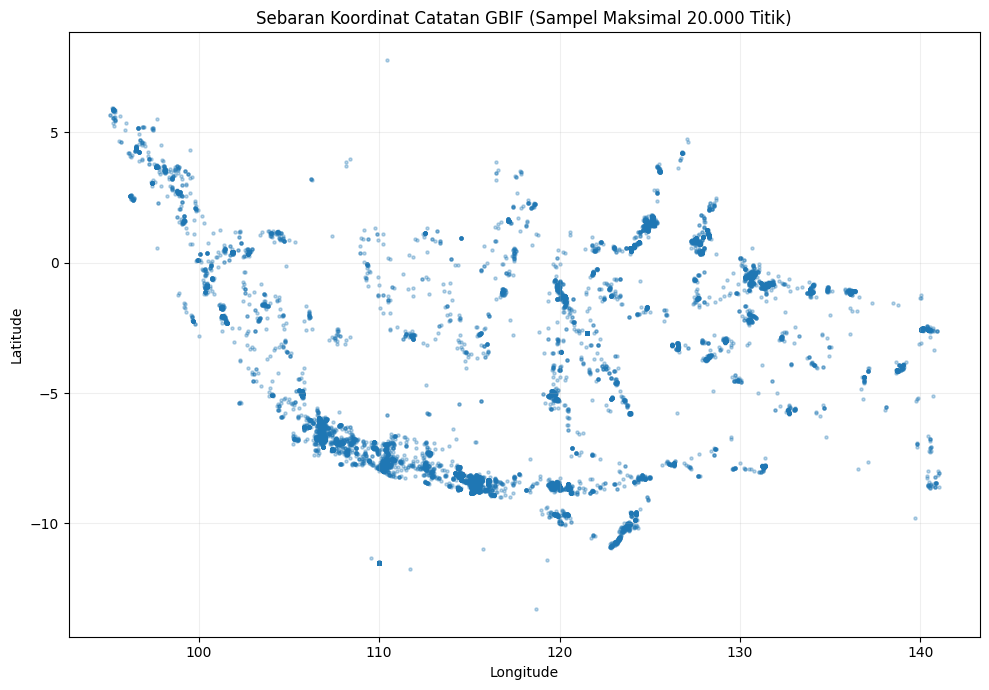

Jumlah catatan dengan koordinat valid: 20,000


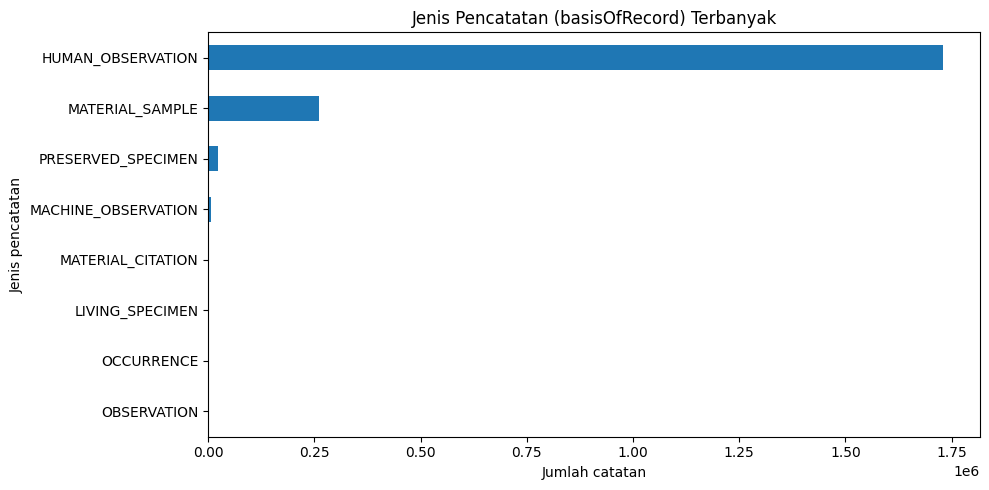

Jenis pencatatan terbanyak: HUMAN_OBSERVATION (1,730,481 catatan).


In [11]:
if {"decimalLongitude", "decimalLatitude"}.issubset(df.columns):
    koordinat = df.copy()
    koordinat["decimalLongitude"] = pd.to_numeric(koordinat["decimalLongitude"], errors="coerce")
    koordinat["decimalLatitude"] = pd.to_numeric(koordinat["decimalLatitude"], errors="coerce")
    koordinat = koordinat.dropna(subset=["decimalLongitude", "decimalLatitude"])
    koordinat = koordinat[
        koordinat["decimalLongitude"].between(-180, 180)
        & koordinat["decimalLatitude"].between(-90, 90)
    ]
    if len(koordinat) > 20000:
        koordinat = koordinat.sample(20000, random_state=RANDOM_STATE)

    plt.figure(figsize=(10, 7))
    plt.scatter(koordinat["decimalLongitude"], koordinat["decimalLatitude"], s=5, alpha=0.3)
    plt.title("Sebaran Koordinat Catatan GBIF (Sampel Maksimal 20.000 Titik)")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()
    print("Jumlah catatan dengan koordinat valid:", f"{len(koordinat):,}")
else:
    print("Kolom decimalLongitude dan/atau decimalLatitude tidak tersedia; scatter plot dilewati.")

if "basisOfRecord" in df.columns:
    basis_counts = df["basisOfRecord"].fillna("Unknown").value_counts().head(10).sort_values()
    if not basis_counts.empty:
        plt.figure(figsize=(10, 5))
        basis_counts.plot(kind="barh")
        plt.title("Jenis Pencatatan (basisOfRecord) Terbanyak")
        plt.xlabel("Jumlah catatan")
        plt.ylabel("Jenis pencatatan")
        plt.tight_layout()
        plt.show()
        print("Jenis pencatatan terbanyak:", basis_counts.index[-1], f"({basis_counts.iloc[-1]:,} catatan).")

## 12. Ringkasan Data Understanding (Apa–Mengapa–Bagaimana)

Bagian ini merangkum hasil pemahaman dataset untuk menjadi dasar penyusunan proses cleaning dan feature engineering pada notebook kedua.

In [ ]:
ringkasan = pd.DataFrame([
    ["Apa", f"Dataset berisi {len(df):,} baris dan {len(kolom_sumber):,} kolom pada file sumber. Notebook memuat {len(df.columns)} kolom yang relevan untuk EDA."],
    ["Mengapa", "Memahami struktur, kelengkapan, validitas, dan pola awal catatan biodiversitas sebelum membentuk unit analisis clustering."],
    ["Bagaimana", "Memeriksa tipe data, missing values, duplikasi, validitas koordinat/tahun, distribusi taksonomi, wilayah, tren tahunan, dan sebaran koordinat."],
], columns=["Komponen", "Ringkasan"])
display(ringkasan)

print("\nNotebook 01 selesai. Lanjutkan ke 02_data_preparation_clustering.ipynb.")